# Two forecasting agents: quarterly AR(1) versus Focus IPCA

A rule-based agent re-estimates an AR(1) model **once per quarter** from realized quarterly IPCA inflation. A Focus agent uses the published monthly median forecasts already matched in the [rolling Focus panel](ipca_rolling_horizon_comparison.ipynb). At each common origin, both forecast cumulative IPCA over the next **1, 2, and 4 quarters** (3, 6, and 12 months). We compare their errors against the same realized IPCA.

This adapts the quarterly AR(1) re-estimation and simple expectation-rule ideas in [Poledna et al. (2023), *Economic forecasting with an agent-based model*](https://doi.org/10.1016/j.euroecorev.2022.104306). Their model has interacting agents and uses the GDP deflator; here the two agents are **forecasting rules evaluated on historical Brazilian IPCA**, not a reproduction of their economy. The AR(1) paths have no simulated shocks. The Monte Carlo step below resamples paired historical errors to quantify uncertainty in the accuracy comparison.

## 1. Data and forecast timing

The first origin is January 2007, after 20 observed quarter-on-quarter IPCA changes (2002 Q1–2006 Q4). Origins occur in January, April, July, and October through January 2025. We use the last available Focus date in each origin month. By that date, the previous quarter's final IPCA is assumed to be published. We never fit on the current or a future quarter. The expanding estimation window ends at the previous quarter.

The Focus agent's 3-, 6-, and 12-month values compound the corresponding monthly Focus medians (`Indicador = IPCA`, `baseCalculo = 0`). A compound of monthly medians is not the median of individual cumulative forecasts. Both agents are scored against the same forward cumulative change in the IBGE national IPCA index. Run this notebook from the repository root or `projects/` after building the matched panel as described in [data/README.md](data/README.md).

In [1]:
panel_file <- file.path("projects", "data", "ipca_rolling_horizon_comparison_200111_202501.csv")
project_root <- if (file.exists(panel_file)) "." else if (file.exists(file.path("..", panel_file))) ".." else stop("Run ipca_rolling_horizon_comparison.ipynb first")
panel <- read.csv(file.path(project_root, panel_file), stringsAsFactors = FALSE)
index <- read.csv(file.path(project_root, "projects/data/ibge_ipca_monthly_index_200110_202512.csv"), colClasses = c("character", "numeric"))
stopifnot(identical(panel$forecast_month, format(seq(as.Date("2001-11-01"), as.Date("2025-01-01"), by = "month"), "%Y-%m")),
          identical(index$month, format(seq(as.Date("2001-10-01"), as.Date("2025-12-01"), by = "month"), "%Y%m")),
          all(is.finite(index$ipca_index)), all(index$ipca_index > 0),
          length(unique(panel$focus_snapshot)) == 1L)
comparison <- subset(panel, forecast_month >= "2007-01" & substr(forecast_month, 6, 7) %in% c("01", "04", "07", "10"))
row.names(comparison) <- NULL
stopifnot(nrow(comparison) == 73L, comparison$forecast_month[1] == "2007-01",
          tail(comparison$forecast_month, 1) == "2025-01")
quarter_ends <- index[substr(index$month, 5, 6) %in% c("03", "06", "09", "12"), ]
quarterly <- data.frame(end_month = quarter_ends$month[-1L],
                        log_ipca_pct = 100 * diff(log(quarter_ends$ipca_index)))
stopifnot(quarterly$end_month[1] == "200203", all(is.finite(quarterly$log_ipca_pct)))
cat("Focus snapshot:", unique(panel$focus_snapshot), "| matched quarterly origins:", nrow(comparison), "
")

Focus snapshot: 20261029T204913Z | matched quarterly origins: 73 


## 2. Simulate the quarterly AR(1) agent

For quarter-on-quarter log IPCA inflation, fit $y_q = a + b y_{q-1} + e_q$ by ordinary least squares on all quarters available before the origin. The agent recursively predicts four quarterly rates using its own previous prediction after the first step. Cumulative forecasts are $100[\exp(\sum_{j=1}^{h}\hat y_{q+j}/100)-1]$. Refitting occurs once at each quarterly origin. `training_end_month` and `training_quarters` make the information boundary auditable.

In [2]:
horizons <- c(3L, 6L, 12L)
quarter_steps <- c(1L, 2L, 4L)
comparison$training_end_month <- NA_character_
comparison$training_quarters <- NA_integer_
comparison$ar1_alpha <- NA_real_
comparison$ar1_phi <- NA_real_
for (h in horizons) {
  comparison[[paste0("ar1_forecast_", h, "m_pct")]] <- NA_real_
  comparison[[paste0("ar1_error_", h, "m_pp")]] <- NA_real_
}
for (i in seq_len(nrow(comparison))) {
  origin <- comparison$forecast_month[i]
  previous_end <- format(as.Date(paste0(origin, "-01")) - 1L, "%Y%m")
  end_position <- match(previous_end, quarterly$end_month)
  index_position <- match(previous_end, quarter_ends$month)
  stopifnot(!is.na(end_position), end_position >= 20L, !is.na(index_position),
            substr(comparison$forecast_date[i], 1, 7) == origin)
  history <- quarterly$log_ipca_pct[seq_len(end_position)]
  fit <- lm(current ~ previous, data = data.frame(current = history[-1L], previous = history[-length(history)]))
  parameters <- coef(fit)
  if (any(!is.finite(parameters))) stop("Invalid AR(1) fit at ", origin)
  comparison$training_end_month[i] <- previous_end
  comparison$training_quarters[i] <- length(history)
  comparison$ar1_alpha[i] <- parameters[1]
  comparison$ar1_phi[i] <- parameters[2]
  predicted <- numeric(4L)
  lagged <- tail(history, 1L)
  for (step in seq_along(predicted)) {
    predicted[step] <- parameters[1] + parameters[2] * lagged
    lagged <- predicted[step]
  }
  agent_forecast <- 100 * expm1(cumsum(predicted)[quarter_steps] / 100)
  realized_from_index <- 100 * (quarter_ends$ipca_index[index_position + quarter_steps] /
                                  quarter_ends$ipca_index[index_position] - 1)
  for (k in seq_along(horizons)) {
    h <- horizons[k]
    realized <- comparison[[paste0("realized_", h, "m_pct")]][i]
    if (abs(realized_from_index[k] - realized) > 1e-8) stop("Outcome mismatch at ", origin, ", horizon ", h)
    comparison[[paste0("ar1_forecast_", h, "m_pct")]][i] <- agent_forecast[k]
    comparison[[paste0("ar1_error_", h, "m_pp")]][i] <- agent_forecast[k] - realized
  }
}
stopifnot(all(comparison$training_quarters >= 20L),
          all(is.finite(comparison$ar1_phi)),
          all(vapply(comparison[grep("^ar1_error_", names(comparison))], function(x) all(is.finite(x)), logical(1))))
output_file <- file.path(project_root, "projects/data/ipca_quarterly_agent_comparison_200701_202501.csv")
write.csv(comparison, output_file, row.names = FALSE)
print(comparison[c("forecast_month", "forecast_date", "training_end_month", "training_quarters", "ar1_alpha", "ar1_phi", "forecast_12m_pct", "ar1_forecast_12m_pct")][c(1, 2, 72, 73), ], row.names = FALSE, digits = 4)
cat("Saved matched agent forecasts to", output_file, "
")

 forecast_month forecast_date training_end_month training_quarters ar1_alpha
        2007-01    2007-01-31             200612                20    0.8106
        2007-04    2007-04-30             200703                21    0.7952
        2024-10    2024-10-31             202409                91    0.8300
        2025-01    2025-01-31             202412                92    0.8363
 ar1_phi forecast_12m_pct ar1_forecast_12m_pct
  0.5564            4.074                6.721
  0.5598            3.484                6.807
  0.4386            4.135                5.551
  0.4365            5.482                6.102
Saved matched agent forecasts to ../projects/data/ipca_quarterly_agent_comparison_200701_202501.csv 


## 3. Compare agents on the same origins

Signed error is forecast minus realized IPCA, in percentage points. Positive `focus_gain_pp` means the Focus agent has lower mean absolute error (MAE) than the AR(1) agent. Compare agents **within** a horizon; cumulative errors naturally have different scales across horizons.

 horizon_months  n focus_mae_pp ar1_mae_pp focus_gain_pp focus_bias_pp
              3 73       0.3957     0.6482        0.2525       -0.1524
              6 73       0.8661     1.1598        0.2937       -0.3812
             12 73       1.5721     1.8210        0.2489       -0.8925
 ar1_bias_pp focus_rmse_pp ar1_rmse_pp
     0.07511        0.5273       0.834
     0.20315        1.1470       1.512
     0.54599        2.2366       2.227


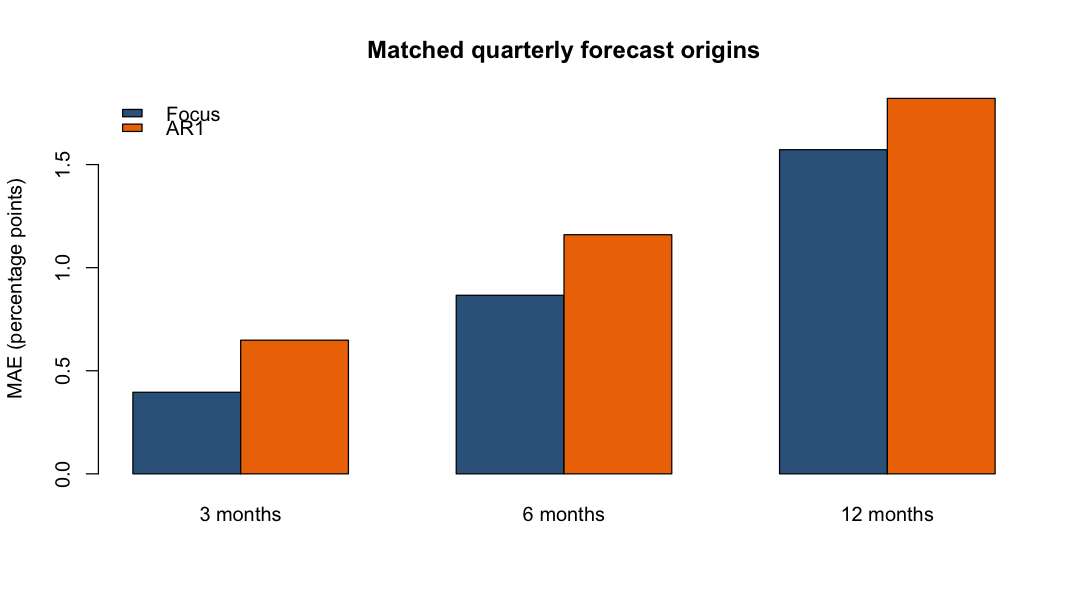

In [3]:
accuracy <- do.call(rbind, lapply(horizons, function(h) {
  focus_error <- comparison[[paste0("error_", h, "m_pp")]]
  ar1_error <- comparison[[paste0("ar1_error_", h, "m_pp")]]
  data.frame(horizon_months = h, n = length(focus_error),
             focus_mae_pp = mean(abs(focus_error)), ar1_mae_pp = mean(abs(ar1_error)),
             focus_gain_pp = mean(abs(ar1_error) - abs(focus_error)),
             focus_bias_pp = mean(focus_error), ar1_bias_pp = mean(ar1_error),
             focus_rmse_pp = sqrt(mean(focus_error^2)), ar1_rmse_pp = sqrt(mean(ar1_error^2)))
}))
print(accuracy, row.names = FALSE, digits = 4)
options(repr.plot.width = 9, repr.plot.height = 5)
mae <- rbind(Focus = accuracy$focus_mae_pp, AR1 = accuracy$ar1_mae_pp)
barplot(mae, beside = TRUE, col = c("steelblue4", "darkorange2"),
        names.arg = paste(horizons, "months"), ylab = "MAE (percentage points)",
        main = "Matched quarterly forecast origins")
legend("topleft", legend = rownames(mae), fill = c("steelblue4", "darkorange2"), bty = "n")

## 4. Monte Carlo uncertainty for the paired accuracy gap

The 12-month outcomes overlap across four adjacent quarterly origins. Resample **paired rows** in circular blocks of four quarters, so the two agents and all horizons remain aligned. Ten thousand bootstrap draws give percentile intervals for the mean difference in absolute error. This samples historical forecast episodes; it does not inject random shocks into the AR(1) rule or simulate a whole economy.

In [4]:
set.seed(20261113)
B <- 10000L
block_length <- 4L
n <- nrow(comparison)
gain <- sapply(horizons, function(h) abs(comparison[[paste0("ar1_error_", h, "m_pp")]]) -
                                  comparison[[paste0("absolute_error_", h, "m_pp")]])
colnames(gain) <- paste(horizons, "months")
boot <- matrix(NA_real_, nrow = B, ncol = length(horizons))
for (b in seq_len(B)) {
  starts <- sample.int(n, ceiling(n / block_length), replace = TRUE)
  positions <- ((rep(starts - 1L, each = block_length) +
                 rep(0:(block_length - 1L), length(starts))) %% n) + 1L
  boot[b, ] <- colMeans(gain[positions[seq_len(n)], , drop = FALSE])
}
interval <- apply(boot, 2L, quantile, probs = c(0.025, 0.975))
uncertainty <- data.frame(horizon_months = horizons, focus_gain_pp = colMeans(gain),
                          lower_95_pp = interval[1L, ], upper_95_pp = interval[2L, ],
                          fraction_focus_better = colMeans(boot > 0))
stopifnot(all(is.finite(as.matrix(uncertainty))))
print(uncertainty, row.names = FALSE, digits = 4)

 horizon_months focus_gain_pp lower_95_pp upper_95_pp fraction_focus_better
              3        0.2525     0.13265      0.3755                1.0000
              6        0.2937     0.07649      0.4948                0.9955
             12        0.2489    -0.22376      0.6918                0.8541


## Interpretation and limits

The AR(1) agent has a deliberately narrow information set: lagged realized IPCA only. Focus aggregates professional forecasts that may use more information. The comparison measures historical forecast accuracy under these two rules, not how agents would interact or change inflation. Estimates may vary with the training start, inflation regime, data revisions, or the assumption that the previous quarter's IPCA was available by each month-end origin. Bootstrap intervals summarize uncertainty in this matched historical sample; they do not guarantee future performance.